# Lesson 6: Eigenvectors and Eigenvalues of the Moment Covariance Matrix

In Lesson 5 we used central moments to find a blob's orientation and, with a bit of extra algebra, its semi-axis lengths. This lesson makes that connection explicit and general: the central moments of *any* blob (not just an ellipse) define a $2\times2$ **covariance matrix**, and the eigenvectors/eigenvalues of that matrix directly give the orientation and size of the *equivalent ellipse* &mdash; the ellipse with the same area and same second-moment spread as the blob.

In [1]:
# Download the sample images used in this lesson, if not already present
import os, urllib.request

for _f in ['glasses_outline.png']:
    _path = f"../img/{_f}"
    if not os.path.exists(_path):
        os.makedirs("../img", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/sbirchfield/sbirchfield.github.io/main/cvintro/img/{_f}", _path)

## Refresher: what are eigenvectors and eigenvalues?

For a square matrix $A$, a nonzero vector $v$ is an **eigenvector** with **eigenvalue** $\lambda$ if

$$Av = \lambda v$$

In words: applying $A$ to $v$ doesn't rotate $v$ off its own line &mdash; it only *scales* it, by a factor of $\lambda$. Most vectors get both rotated and scaled by $A$; eigenvectors are the special directions that only get scaled.

For a $2\times2$ **symmetric** matrix (like the covariance matrices we'll build below), something even nicer is guaranteed: there are always two eigenvectors, they are perpendicular to each other, and their eigenvalues are real numbers. Geometrically, $A$ takes a circle of unit vectors and stretches it into an ellipse whose axes point along the eigenvectors, with each semi-axis length equal to the corresponding eigenvalue. That picture &mdash; eigenvectors as axis *directions*, eigenvalues as axis *lengths* &mdash; is exactly what we'll exploit for shape analysis below.

eigenvalues : [1.  3.5]
eigenvectors (columns):
 [[ 0.4472136  -0.89442719]
 [-0.89442719 -0.4472136 ]]


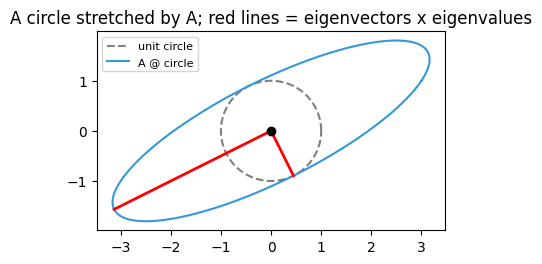

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

A = np.array([[3.0, 1.0],
              [1.0, 1.5]])

eigvals, eigvecs = np.linalg.eigh(A)  # ascending order
print('eigenvalues :', eigvals)
print('eigenvectors (columns):\n', eigvecs)

theta = np.linspace(0, 2 * np.pi, 200)
circle = np.stack([np.cos(theta), np.sin(theta)])  # unit circle, as column vectors
ellipse = A @ circle  # apply A to every point on the circle

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(circle[0], circle[1], '--', color='gray', label='unit circle')
ax.plot(ellipse[0], ellipse[1], color='#3498db', label='A @ circle')
for val, vec in zip(eigvals, eigvecs.T):
    ax.plot([0, val * vec[0]], [0, val * vec[1]], color='red', linewidth=2)
ax.scatter(0, 0, color='black', zorder=5)
ax.set_aspect('equal')
ax.legend(loc='upper left', fontsize=8)
ax.set_title('A circle stretched by A; red lines = eigenvectors x eigenvalues')
plt.show()

In this animation, a circle of vectors is morphed through A, from the identity (start) to A itself (end). Watch how every ordinary vector (gray) rotates away from its starting direction as the circle deforms into an ellipse, while the two eigenvectors (red, blue) stay on the same line the entire time — they only stretch, by exactly their eigenvalue.

<img src="https://github.com/sbirchfield/sbirchfield.github.io/blob/main/cvintro/animations/eigen_demo.gif?raw=1" alt="Animated walkthrough of a matrix transforming a circle into an ellipse, showing eigenvectors do not rotate" style="display: block; margin: 0 auto; max-width: 650px;">

### From one eigenvector to both at once: diagonalization

$Av = \lambda v$ above holds for a single eigenvector. Stack *both* eigenvectors as the columns of a matrix $P = \begin{bmatrix}v_1 & v_2\end{bmatrix}$, and both eigenvalues on the diagonal of $\Lambda = \begin{bmatrix}\lambda_1 & 0\\0 & \lambda_2\end{bmatrix}$. Then $Av_1=\lambda_1 v_1$ and $Av_2=\lambda_2 v_2$, side by side, become one matrix equation:

$$AP = P\Lambda$$

Because $A$ is symmetric, its eigenvectors are not just perpendicular but *orthonormal*, which makes $P$ an **orthogonal** matrix (inverting it is just a transpose: $P^{-1} = P^\top$). That lets us solve for $A$ itself:

$$A = P\Lambda P^\top$$

This is the **diagonalization** of $A$, and geometrically it's three steps: $P^\top$ *rotates* coordinates into the eigenvector frame, $\Lambda$ *scales* along those (now axis-aligned) directions independently, and $P$ *rotates back*. Read in that rotated frame, $A$ is genuinely diagonal &mdash; the off-diagonal entry, which mixes $x$ and $y$ together, is exactly zero. When $A$ is a covariance matrix, that off-diagonal entry is $\mu_{11}$: diagonalizing the covariance matrix and finding the ellipse's own natural axes are the same operation &mdash; both mean rotating into the one coordinate frame where the blob's spread in $x$ and $y$ no longer mixes at all.

In [3]:
P = eigvecs
Lam = np.diag(eigvals)

print('A @ P:\n', np.round(A @ P, 4))
print('P @ Lambda:\n', np.round(P @ Lam, 4))
print('max |A@P - P@Lambda| (should be ~0):', np.abs(A @ P - P @ Lam).max())
print()

reconstructed = P @ Lam @ P.T
print('P @ Lambda @ P.T (reconstructed A):\n', np.round(reconstructed, 4))
print('original A:\n', A)
print('max |reconstructed - A|:', np.abs(reconstructed - A).max())
print()

diagonalized = P.T @ A @ P  # A, read in the eigenvector frame
print('P.T @ A @ P (A in its own eigenbasis -- should be diagonal):\n', np.round(diagonalized, 4))

A @ P:
 [[ 0.4472 -3.1305]
 [-0.8944 -1.5652]]
P @ Lambda:
 [[ 0.4472 -3.1305]
 [-0.8944 -1.5652]]
max |A@P - P@Lambda| (should be ~0): 1.1102230246251565e-16

P @ Lambda @ P.T (reconstructed A):
 [[3.  1. ]
 [1.  1.5]]
original A:
 [[3.  1. ]
 [1.  1.5]]
max |reconstructed - A|: 2.220446049250313e-16

P.T @ A @ P (A in its own eigenbasis -- should be diagonal):
 [[ 1.  -0. ]
 [ 0.   3.5]]


In this animation, the same matrix A is applied as three separate steps instead of one: first Pᵀ rotates the eigenvectors onto the x/y axes, then Λ stretches along those axes by the eigenvalues, then P rotates everything back. The matrix currently being applied is highlighted in orange. The result lands on the exact same ellipse as applying A directly above.

<img src="https://github.com/sbirchfield/sbirchfield.github.io/blob/main/cvintro/animations/diagonalization_demo.gif?raw=1" alt="Animated walkthrough of diagonalization A = P Lambda P transpose, applied as three sequential steps" style="display: block; margin: 0 auto; max-width: 750px;">

## From central moments to a covariance matrix

Treat a blob's pixels as samples from a 2D distribution. Its covariance matrix, in terms of the central moments $\mu_{ij}$ and area $\mu_{00}=m_{00}$, is

$$A = \frac{1}{m_{00}}\begin{bmatrix}\mu_{20} & \mu_{11} \\ \mu_{11} & \mu_{02}\end{bmatrix}$$

This is exactly the same formula used for the covariance matrix of a scatter of points $(x,y)$, just weighted by pixel membership instead of by sample index. The off-diagonal $\mu_{11}$ term is precisely the entry that mixing $x$ and $y$ leaves behind, so this is exactly the matrix we want to **diagonalize**: its eigenvectors will point along the blob's own major and minor axes &mdash; the directions of greatest and least spread &mdash; and its eigenvalues will measure how much spread there is along each. This same operation, applied to a covariance matrix of general (not necessarily 2D pixel) data, is called **principal component analysis (PCA)**: the eigenvectors ranked by eigenvalue are the *principal components*, the directions of greatest variance in the data, and they're often used to reduce a high-dimensional dataset down to just its most informative few directions.

In [4]:
def covariance_from_moments(binary):
    m = cv2.moments(binary, binaryImage=True)
    cx, cy = m['m10'] / m['m00'], m['m01'] / m['m00']
    cov = np.array([[m['mu20'], m['mu11']],
                     [m['mu11'], m['mu02']]]) / m['m00']
    return cov, (cx, cy)

## Eigen decomposition gives orientation and size

`np.linalg.eigh` returns eigenvalues in ascending order along with their eigenvectors (as columns). For a filled ellipse with semi-axes $a \ge b$, the eigenvalues work out to $\lambda_{\max} = a^2/4$ and $\lambda_{\min}=b^2/4$, so

$$a = 2\sqrt{\lambda_{\max}}, \qquad b = 2\sqrt{\lambda_{\min}}$$

and the corresponding eigenvectors point along the major and minor axes.  Note that the angle of the major axis is the same as the angle computed in Lesson 5.

*Notice the square root here, which was absent in the refresher above: there, the eigenvalues of the arbitrary matrix *A* were themselves the stretch factors applied to the unit circle. Here, the eigenvalues of the covariance matrix are variances (built from squared coordinate deviations), so recovering an actual axis length means undoing that square, hence the square root.*

In [9]:
def principal_axes(binary):
    cov, center = covariance_from_moments(binary)
    eigvals, eigvecs = np.linalg.eigh(cov)  # ascending order
    semi_axes = 2 * np.sqrt(np.clip(eigvals, 0, None))
    # reorder so index 0 is major (largest), index 1 is minor
    order = [1, 0]
    # eigvecs[:, order] has the two eigenvectors as its COLUMNS; transpose so that
    # unpacking it below (which iterates over ROWS) hands back the two actual eigenvectors,
    # not a scrambled mix of their x- and y-components
    return center, semi_axes[order], eigvecs[:, order].T


def draw_axes(ax, binary, color='red'):
    center, (a, b), (v_major, v_minor) = principal_axes(binary)
    cx, cy = center
    ax.imshow(binary, cmap='gray')
    for length, vec, lw in [(a, v_major, 2.5), (b, v_minor, 1.5)]:
        dx, dy = length * vec
        ax.plot([cx - dx, cx + dx], [cy - dy, cy + dy], c=color, linewidth=lw)
    ax.scatter(cx, cy, c=color, marker='x', s=60)
    ax.axis('off')
    return center, (a, b)

### Sanity check: a known ellipse

As in Lesson 5, we draw an ellipse with known parameters and confirm the eigen-based estimate recovers them &mdash; but this time we plot *both* axes, not just the major one.

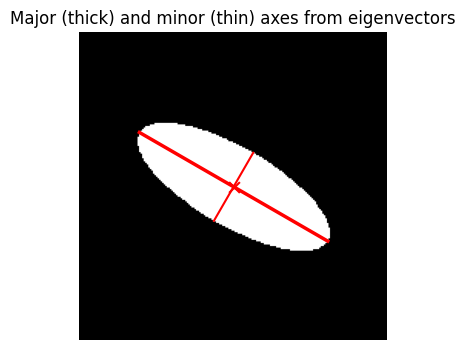

recovered semi-axes: a=70.6, b=25.5  (drawn with 70, 25)


In [6]:
binary = np.zeros((200, 200), dtype=np.uint8)
cv2.ellipse(binary, (100, 100), (70, 25), 30, 0, 360, 255, -1)

fig, ax = plt.subplots(figsize=(4, 4))
center, (a, b) = draw_axes(ax, binary)
ax.set_title('Major (thick) and minor (thin) axes from eigenvectors')
plt.show()

print(f'recovered semi-axes: a={a:.1f}, b={b:.1f}  (drawn with 70, 25)')

## It works on arbitrary shapes, too

The real power of this approach is that it doesn't require the blob to be an ellipse at all. Every binary shape has *some* equivalent ellipse &mdash; the one that matches its area, centroid, and second-moment spread. This gives a compact 5-number summary (center, two semi-axis lengths, orientation) of an arbitrarily shaped blob.

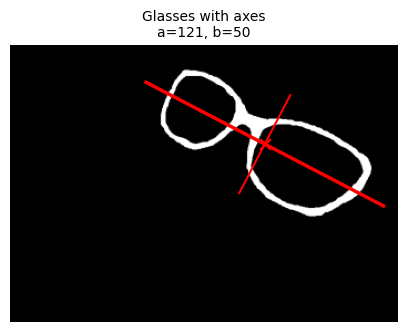

In [7]:
im_glasses = cv2.imread('../img/glasses_outline.png', cv2.IMREAD_GRAYSCALE)

shapes = {'Glasses': im_glasses}

fig, ax = plt.subplots(figsize=(5, 4))
center, (a, b) = draw_axes(ax, im_glasses)
ax.set_title(f'Glasses with axes\na={a:.0f}, b={b:.0f}', fontsize=10)
plt.show()

<p class="image-attribution">Image source: Stan Birchfield</p>

Notice the equivalent ellipse doesn't try to trace the shape's boundary &mdash; it summarizes the *distribution of mass* around the centroid, so it cuts across the narrow bridge between the two lenses rather than following it, and its outline falls outside the lenses near the top and bottom where the glasses taper.

## Eccentricity: how elongated is a shape?

The ratio of the eigenvalues (or semi-axes) gives a single number describing elongation, independent of orientation and overall size:

$$\text{eccentricity} = \sqrt{1 - \frac{\lambda_{\min}}{\lambda_{\max}}}$$

This ranges from 0 (a circle, both axes equal) to nearly 1 (a very thin, elongated shape).

In [8]:
print(f'{"shape":>10} {"a":>6} {"b":>6} {"eccentricity":>13}')
for name, img in shapes.items():
    _, (a, b), _ = principal_axes(img)
    ecc = np.sqrt(1 - (b / a) ** 2)
    print(f'{name:>10} {a:6.1f} {b:6.1f} {ecc:13.3f}')

     shape      a      b  eccentricity
   Glasses  120.9   49.9         0.911


### Exercises

1. Draw a perfect circle and confirm its eccentricity is (close to) 0.
2. Overlay the *actual* fitted ellipse outline (not just the axis lines) using `cv2.ellipse` with the center, `(2a, 2b)` as the full axes lengths, and the orientation angle from the eigenvectors. Compare it to `cv2.fitEllipse` applied to the shape's contour &mdash; do they agree?
3. Run `principal_axes` on the filled blob of `glasses` (after flood fill)). How much do `a`, `b`, and the eccentricity change? Does that match your intuition for how moments depend on *where* mass sits, not just the overall silhouette?

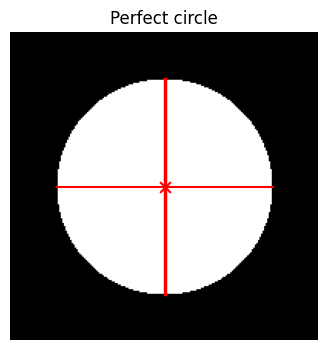

In [10]:
# Exercise 1
circle = np.zeros((200, 200), dtype=np.uint8)
cv2.circle(circle, (100, 100), 70, 255, -1)

fig, ax = plt.subplots(figsize=(4, 4))
center, (a, b) = draw_axes(ax, circle)
ax.set_title('Perfect circle')
plt.show()


In [12]:
# Show the eccentric
_, (a,b), _ = principal_axes(circle)
ecc = np.sqrt(1 - (b / a) ** 2)
print(f'eccentricity: {ecc:.3f}') # Yup, it close to zero because both major and minor axes are equal

eccentricity: 0.000


In [14]:
# Exercise 2
cv2.ellipse(circle, center, (2*a, 2*b), 30, 0, 360, 255, 1)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(circle, cmap='gray')
ax.axis('off')
plt.show()

error: OpenCV(4.14.0) :-1: error: (-5:Bad argument) in function 'ellipse'
> Overload resolution failed:
>  - Can't parse 'center'. Sequence item with index 0 has a wrong type
>  - ellipse() takes at most 5 arguments (8 given)
>  - Can't parse 'center'. Sequence item with index 0 has a wrong type
>  - ellipse() takes at most 5 arguments (8 given)


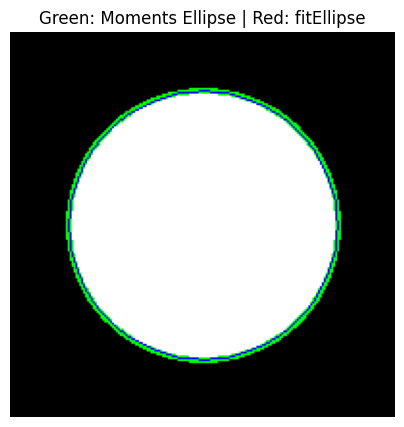

In [16]:
# Exercise 2: Correctly overlay the fitted ellipse and compare with cv2.fitEllipse
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Re-initialize circle & get principal axes parameters
circle_img = np.zeros((200, 200), dtype=np.uint8)
cv2.circle(circle_img, (100, 100), 70, 255, -1)

center, (a, b), (v_major, v_minor) = principal_axes(circle_img)

# Calculate orientation angle in degrees from the major eigenvector
angle_rad = np.arctan2(v_major[1], v_major[0])
angle_deg = np.degrees(angle_rad)

# Create a visualization image
overlay = cv2.cvtColor(circle_img, cv2.COLOR_GRAY2BGR)

# Draw our moment-based ellipse (OpenCV expects center and semi-axes as integer tuples)
cv2.ellipse(
    overlay,
    (int(round(center[0])), int(round(center[1]))),
    (int(round(a)), int(round(b))),
    angle_deg,
    0, 360,
    (0, 255, 0),  # Green
    2
)

# 2. Fit an ellipse using cv2.fitEllipse on contours for comparison
contours, _ = cv2.findContours(circle_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
if contours:
    fitted_ellipse = cv2.fitEllipse(contours[0])
    cv2.ellipse(overlay, fitted_ellipse, (255, 0, 0), 1)  # Red

# Display the results
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Green: Moments Ellipse | Red: fitEllipse")
plt.axis('off')
plt.show()


### Step 1: Load the Original Glasses Outline Image
First, we load the original `glasses_outline.png` image and visualize it.

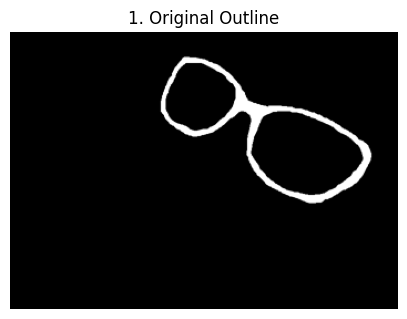

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load original outline in grayscale
im_glasses = cv2.imread('../img/glasses_outline.png', cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(5, 4))
plt.imshow(im_glasses, cmap='gray')
plt.title("1. Original Outline")
plt.axis('off')
plt.show()

### Step 2: Extract and Fill the Contours
Next, we find the contours of the lenses and fill them to create a solid binary blob.

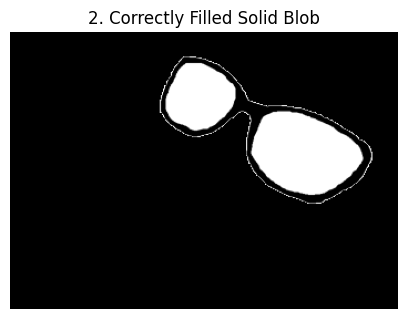

In [27]:
glasses_filled = im_glasses.copy()

# 1. Flood-fill the background with white (255) starting from the top-left corner (0,0)
h, w = glasses_filled.shape
mask = np.zeros((h + 2, w + 2), dtype=np.uint8)
cv2.floodFill(glasses_filled, mask, (0, 0), 255)

# 2. Invert the image so that the background becomes black (0) and the glasses (now fully solid) become white (255)
glasses_filled = cv2.bitwise_not(glasses_filled)

plt.figure(figsize=(5, 4))
plt.imshow(glasses_filled, cmap='gray')
plt.title("2. Correctly Filled Solid Blob")
plt.axis('off')
plt.show()

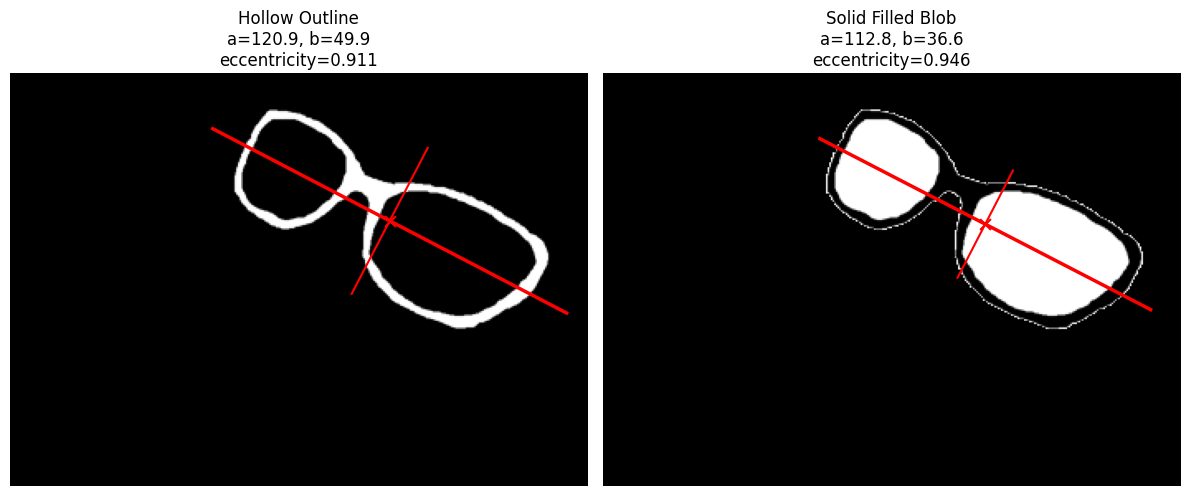

Outline: a = 120.9, b = 49.9, Eccentricity = 0.911
Filled:  a = 112.8, b = 36.6, Eccentricity = 0.946


In [28]:
# Recalculate and display the updated comparison using our flood-filled image
center_out, (a_out, b_out), _ = principal_axes(im_glasses)
ecc_out = np.sqrt(1 - (b_out / a_out) ** 2)

center_fill, (a_fill, b_fill), _ = principal_axes(glasses_filled)
ecc_fill = np.sqrt(1 - (b_fill / a_fill) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

draw_axes(axes[0], im_glasses)
axes[0].set_title(f'Hollow Outline\na={a_out:.1f}, b={b_out:.1f}\neccentricity={ecc_out:.3f}')

draw_axes(axes[1], glasses_filled)
axes[1].set_title(f'Solid Filled Blob\na={a_fill:.1f}, b={b_fill:.1f}\neccentricity={ecc_fill:.3f}')

plt.tight_layout()
plt.show()

print(f"Outline: a = {a_out:.1f}, b = {b_out:.1f}, Eccentricity = {ecc_out:.3f}")
print(f"Filled:  a = {a_fill:.1f}, b = {b_fill:.1f}, Eccentricity = {ecc_fill:.3f}")